In [1]:
import tensorflow as tf #tensorflow v.1

In [2]:
from tensorflow import keras # keras 2.0

In [3]:
import keras # keras 3.0

### =====================================================================

## 1. Installing Keras

In [4]:
!pip install keras


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!pip install tensorflow


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### =====================================================================

# Let's build our 1st Artificial Deep Neural Network(ANN)

## 1. Import Necessary Libraries

In [95]:
import keras
from matplotlib import pyplot as plt
import pandas as pd
#from tensorflow import keras

## 2. Data Collection

In [96]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

## 3. Data Understanding

In [97]:
x_train.shape,y_train.shape

((50000, 32, 32, 3), (50000, 1))

In [98]:
x_test.shape,y_test.shape

((10000, 32, 32, 3), (10000, 1))

In [99]:
assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

### 3.1 Let's see how one image looks like

In [100]:
pd.set_option('display.max_columns', 30)

In [101]:
pd.DataFrame(x_train[10000].reshape(1, -1))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,3057,3058,3059,3060,3061,3062,3063,3064,3065,3066,3067,3068,3069,3070,3071
0,35,25,26,27,21,21,25,20,19,26,18,18,24,15,15,...,172,170,171,170,168,169,170,168,169,168,167,168,166,166,168


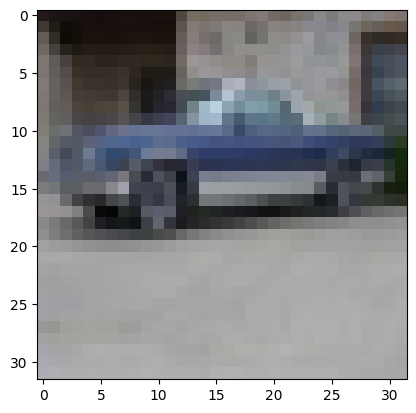

In [102]:
plt.imshow(x_train[10000],cmap = "grey")

## 4. Data Preparation

### Let's Normalize this for Faster processing

In [103]:
x_train = x_train/255.0
x_test  = x_test/255.0

In [104]:
x_train.min(), x_train.max()

(np.float64(0.0), np.float64(1.0))

In [105]:
x_test.min(), x_test.max(),

(np.float64(0.0), np.float64(1.0))

## 5. Model Building

In [106]:
from keras.models import Sequential
from keras.layers import Flatten,Dense

In [107]:
model = Sequential()
model.add(layer = Flatten())
model.add(Dense(units = 200,activation="relu"))
model.add(Dense(units = 100,activation="relu"))
model.add(Dense(units = 30,activation="relu"))
model.add(Dense(units = 10,activation="softmax"))
#model.summary()

In [108]:
model.compile(optimizer='rmsprop',loss="sparse_categorical_crossentropy")#,metrics=["sparse_categorical_accuracy"])

## 6. Model Training || 7. Model Testing || 8. Model Evaluation

In [109]:
model.fit(x=x_train, y=y_train,batch_size=32,epochs=10,validation_data = (x_test,y_test))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 1.9656 - val_loss: 1.8273
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.7465 - val_loss: 1.7260
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.6608 - val_loss: 1.6276
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.6091 - val_loss: 1.6234
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.5801 - val_loss: 1.7027
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.5566 - val_loss: 1.6577
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.5346 - val_loss: 1.6302
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.5243 - val_loss: 1.5472
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.5091 - val_loss: 1.5997
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 1.4994 - val_loss: 1.5855


In [110]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 200)                 │         614,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 100)                 │          20,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 30)                  │           3,030 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 10)                  │             310 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,276,082 (4.87 MB)

 Trainable params: 638,040 (2.43 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 638,042 (2.43 MB)

## 9. Manual Model Prediction

In [111]:
y_pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [112]:
y_test[400]

array([9], dtype=uint8)

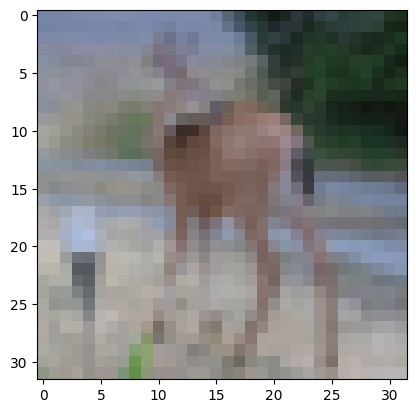

In [113]:
plt.imshow(x_test[100])

In [114]:
import numpy as np
np.argmax(y_pred[100])

np.int64(7)

## =======================================================

## FINAL POINT: Let's Test for outside new data

### Step 1: Let's take out the model intelligence file

In [115]:
model.save("image_classification.h5")

## Step 2: Image Load

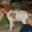

In [116]:
from PIL import Image
img_path = r"C:\Users\vicky\Downloads\0000 (1).jpg"
image = Image.open(img_path)
image = image.convert(mode = "RGB")
image = image.resize(size = (32,32))
image             

In [117]:
from PIL import Image
img_path = r"C:\Users\vicky\Downloads\0000 (1).jpg"
image = Image.open(img_path).convert("RGB").resize((32,32))
image = np.array(image)
image

array([[[ 80,  66,  37],
        [ 78,  64,  35],
        [ 88,  74,  47],
        ...,
        [ 36,  22,  13],
        [ 28,  13,   8],
        [ 29,  14,   9]],

       [[ 85,  71,  42],
        [ 75,  61,  32],
        [ 98,  82,  56],
        ...,
        [ 33,  19,  10],
        [ 48,  33,  26],
        [ 51,  36,  29]],

       [[ 86,  70,  44],
        [ 89,  73,  47],
        [117, 100,  72],
        ...,
        [ 60,  46,  37],
        [ 85,  68,  60],
        [ 59,  42,  34]],

       ...,

       [[105,  91,  82],
        [108,  96,  84],
        [109, 101,  88],
        ...,
        [  9,  25,  41],
        [ 14,  30,  45],
        [ 29,  43,  56]],

       [[118, 101,  94],
        [117, 102,  95],
        [118, 108,  98],
        ...,
        [ 39,  49,  59],
        [ 40,  49,  58],
        [ 29,  38,  45]],

       [[137, 119, 115],
        [132, 117, 110],
        [127, 114, 106],
        ...,
        [ 76,  85,  92],
        [ 64,  69,  75],
        [ 21,  26,  30]]

In [118]:
predict_image(image)

NameError: name 'predict_image' is not defined

## Step 3: Let's do the Prediction

In [119]:
from keras.models import load_model
image_color = load_model("image_classification.h5")

In [120]:
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

def colored_image(image):
    image = np.array(image)/255.0
    image = np.expand_dims(image, axis = 0)
    print(image.shape)
    prediction = image_color.predict(image)  # use the MODEL here
    index = np.argmax(prediction)
    confidence = np.max(prediction) * 100
    print(f"Prediction: {class_names[index]} ({confidence:.1f}%)")
    return class_names[index]

In [121]:
colored_image(image)

(1, 32, 32, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Prediction: cat (27.7%)


'cat'

## THE END!!

### =====================================================================